# Linear mixed models: the basics with `sleepstudy` and `Dyestuff`

This notebook walks through the basic workflow of fitting linear mixed models (LMMs) with
`lme4` for Python:

* `lmer()` with REML (the default) and ML estimation;
* random intercepts, correlated random intercepts and slopes `(Days | Subject)`, and
  uncorrelated ones `(Days || Subject)`;
* the extractors `summary`, `fixef`, `ranef`, `coef`, `VarCorr`, `logLik`, `AIC`;
* likelihood ratio tests with `anova`;
* singular fits and `isSingular` (`Dyestuff2`);
* R-string formulas next to the symbolic Python formula API;
* lme4's diagnostic plots (`plot.merMod`, `qqmath`, `dotplot(ranef(.))`), drawn with matplotlib.

Every number is compared with the output of R 4.6.2 + lme4 2.1.0 at the end of each section.

## Source

* lme4 help pages: [`?lmer`](https://github.com/lme4/lme4/blob/master/man/lmer.Rd),
  [`?sleepstudy`](https://github.com/lme4/lme4/blob/master/man/sleepstudy.Rd),
  [`?Dyestuff`](https://github.com/lme4/lme4/blob/master/man/Dyestuff.Rd),
  [`?plot.merMod`](https://github.com/lme4/lme4/blob/master/man/plot.merMod.Rd),
  [`?ranef`](https://github.com/lme4/lme4/blob/master/man/ranef.Rd)
* D. Bates, M. Mächler, B. Bolker, S. Walker (2015). *Fitting Linear Mixed-Effects Models Using lme4.*
  Journal of Statistical Software 67(1). <https://doi.org/10.18637/jss.v067.i01>
  (sections 1, 2.1 and 5: the `sleepstudy` example, `fm1`/`fm2`, `anova`).
* The R script that produced the reference values: [`r/01_linear_mixed_models.R`](r/01_linear_mixed_models.R).

The original R code:

```r
library(lme4)
## ?lmer
(fm1 <- lmer(Reaction ~ Days + (Days | Subject), sleepstudy))
summary(fm1)
plot(fm1)                                   # residuals vs fitted values
fm1_ML <- update(fm1, REML = FALSE)
(fm2 <- lmer(Reaction ~ Days + (Days || Subject), sleepstudy))
anova(fm1, fm2)

## JSS paper: extractors and a random-intercept model
fixef(fm1); ranef(fm1); coef(fm1); VarCorr(fm1)
fm0 <- lmer(Reaction ~ Days + (1 | Subject), sleepstudy)
anova(fm0, fm2, fm1)

## ?sleepstudy
(fm1s <- lmer(Reaction ~ Days + (Days|Subject), sleepstudy, subset = Days >= 2))
(fm2s <- lmer(Reaction ~ Days + (1|Subject) + (0+Days|Subject), sleepstudy, subset = Days >= 2))

## ?Dyestuff
(fm1d <- lmer(Yield ~ 1|Batch, Dyestuff))
(fm2d <- lmer(Yield ~ 1|Batch, Dyestuff2))  # boundary (singular) fit
isSingular(fm2d)

## ?plot.merMod, ?ranef
plot(fm1, resid(., scaled = TRUE) ~ fitted(.) | Subject, abline = 0)
plot(fm1, Subject ~ resid(., scaled = TRUE))
qqmath(fm1)
dotplot(ranef(fm1, condVar = TRUE))
qqmath(ranef(fm1, condVar = TRUE))
```

## Setup

In [1]:
import json

import numpy as np
import pandas as pd
from numpy.testing import assert_allclose

import matplotlib
import matplotlib.pyplot as plt

import lme4
from lme4 import lmer, V, load_dataset

%matplotlib inline
pd.set_option("display.width", 120)

with open("reference/01_linear_mixed_models.json") as f:
    R = json.load(f)


def na(v):
    """jsonlite writes NA as the string "NA" (and length-1 vectors as scalars)"""
    v = v if isinstance(v, list) else [v]
    return np.array([np.nan if x == "NA" else x for x in v], dtype=float)


def check_fit(m, r, rtol=1e-6):
    """compare a fitted LMM with the R summary written by fitinfo() in the R script"""
    if m.isREML():
        assert_allclose(m.REMLcrit(), r["REMLcrit"], rtol=1e-8)
    else:
        assert_allclose(m.deviance(), r["deviance"], rtol=1e-8)
    assert_allclose(float(m.logLik()), r["logLik"], rtol=1e-8)
    assert m.logLik().df == r["df"]
    assert_allclose([m.AIC(), m.BIC()], [r["AIC"], r["BIC"]], rtol=1e-8)
    assert_allclose(m.theta, na(r["theta"]), rtol=rtol, atol=1e-7)
    assert_allclose(m.sigma(), r["sigma"], rtol=rtol)
    assert list(m.fixef().index) == list(r["fixef"])
    assert_allclose(m.fixef().to_numpy(), list(r["fixef"].values()), rtol=rtol)
    se = np.sqrt(np.diag(np.asarray(m.vcov())))
    assert_allclose(se, na(r["se"]), rtol=rtol)
    vc = m.VarCorr().as_data_frame()
    assert list(vc["grp"]) == list(np.atleast_1d(r["vc_grp"]))
    assert_allclose(vc["sdcor"].to_numpy(), na(r["vc_sdcor"]), rtol=rtol, atol=1e-7)
    assert bool(m.isSingular()) == r["isSingular"]
    assert m.nobs() == r["nobs"]


def check_ranef(m, r, rtol=1e-6):
    rr = m.ranef(condVar=True).as_data_frame()
    assert list(rr["grp"]) == list(r["grp"]) and list(rr["term"]) == list(r["term"])
    scale = np.max(np.abs(r["condval"])) + 1e-300
    assert_allclose(rr["condval"].to_numpy(), r["condval"], rtol=rtol, atol=rtol * scale)
    assert_allclose(rr["condsd"].to_numpy(), r["condsd"], rtol=rtol)
    for g, cf in m.coef().items():
        rc = r["coef"][g]
        assert [str(i) for i in cf.index] == list(np.atleast_1d(rc["levels"]))
        for col in cf.columns:
            assert_allclose(cf[col].to_numpy(), np.atleast_1d(rc[col]), rtol=rtol)


def check_anova(a, r):
    assert_allclose(a["npar"].to_numpy(), r["npar"])
    for col, key in [("AIC", "AIC"), ("BIC", "BIC"), ("logLik", "logLik"), ("-2*log(L)", "deviance")]:
        assert_allclose(a[col].to_numpy(), r[key], rtol=1e-8)
    assert_allclose(a["Chisq"].to_numpy(), na(r["Chisq"]), rtol=1e-6)
    assert_allclose(a["Df"].to_numpy(), na(r["Df"]))
    assert_allclose(a["Pr(>Chisq)"].to_numpy(), na(r["p"]), rtol=1e-6)


print("lme4", lme4.__version__, "| matplotlib", matplotlib.__version__)

lme4 2.1.0a2 | matplotlib 3.11.2


## The data

`sleepstudy` (Belenky et al. 2003): average reaction time (ms) of 18 subjects on each of
10 days of sleep deprivation (days 0–1 were adaptation and training, so the `?sleepstudy`
example also refits on `Days >= 2`). `Subject` is a pandas categorical, the analogue of an R factor.

In [2]:
sleepstudy = load_dataset("sleepstudy")
print(sleepstudy.dtypes)
sleepstudy.head()

Reaction     float64
Days         float64
Subject     category
dtype: object


,Reaction,Days,Subject
0,249.5600,0.0,308
1,258.7047,1.0,308
2,250.8006,2.0,308
3,321.4398,3.0,308
4,356.8519,4.0,308


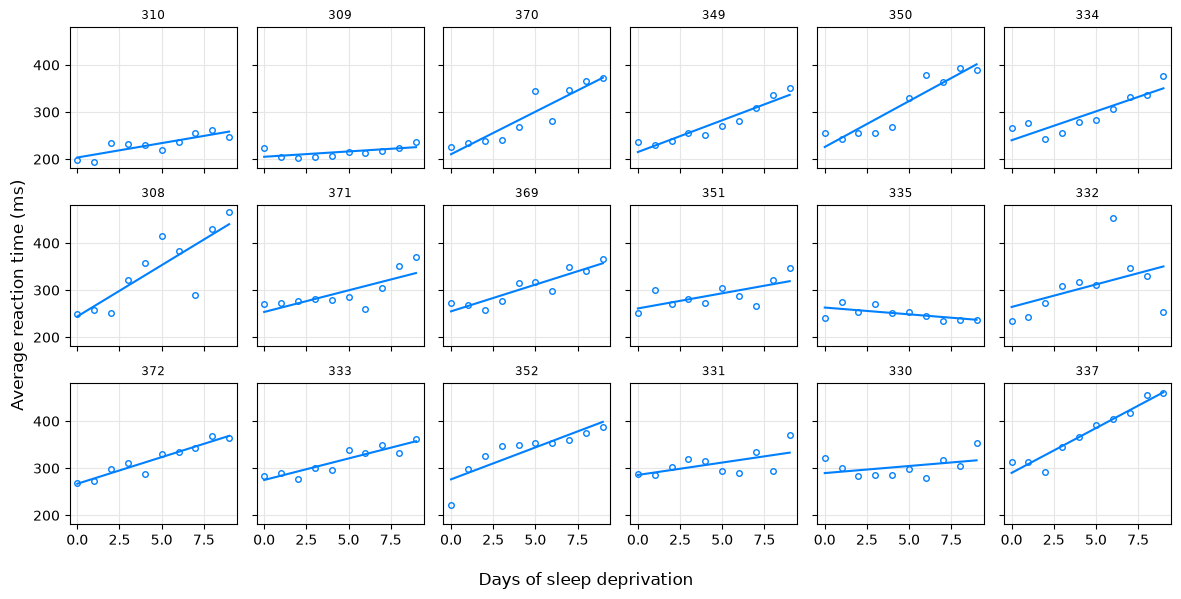

In [3]:
# one panel per subject with the within-subject least-squares line, as in the ?sleepstudy lattice plot
fig, axes = plt.subplots(3, 6, figsize=(12, 6), sharex=True, sharey=True)
order = (sleepstudy.groupby("Subject", observed=True)
         .apply(lambda d: np.polyfit(d.Days, d.Reaction, 1)[1], include_groups=False)
         .sort_values().index)
for ax, s in zip(axes.ravel(), order):
    d = sleepstudy[sleepstudy.Subject == s]
    ax.plot(d.Days, d.Reaction, "o", mfc="none", color="#0080ff", ms=4)
    b = np.polyfit(d.Days, d.Reaction, 1)
    ax.plot([0, 9], np.polyval(b, [0, 9]), color="#0080ff")
    ax.set_title(str(s), fontsize="small")
    ax.grid(color="#e6e6e6")
fig.supxlabel("Days of sleep deprivation")
fig.supylabel("Average reaction time (ms)")
fig.tight_layout()

## Correlated random intercepts and slopes: `fm1`

The model has a fixed intercept and slope for `Days`, and for each subject a random
intercept and a random slope, with a 2×2 unstructured covariance matrix. It is fitted by REML
by default. The formula can be given as an R string or, equivalently, built from symbolic
variables: Python has no binary `~`, so the response is separated with `==`.

In [4]:
fm1 = lmer("Reaction ~ Days + (Days | Subject)", data=sleepstudy)

Reaction, Days, Subject = V("Reaction Days Subject")
fm1_sym = lmer(Reaction == Days + (Days | Subject), data=sleepstudy)

print(fm1_sym.formula())
assert fm1_sym.REMLcrit() == fm1.REMLcrit()
print(fm1)

Reaction ~ Days + (Days | Subject)
Linear mixed model fit by REML ['lmerMod']
Formula: Reaction ~ Days + (Days | Subject)
   Data: sleepstudy
REML criterion at convergence: 1743.628
Random effects:
 Groups   Name        Std.Dev. Corr 
 Subject  (Intercept) 24.741        
          Days         5.922   0.07 
 Residual             25.592        
Number of obs: 180, groups:  Subject, 18
Fixed Effects:
(Intercept)         Days  
     251.41        10.47  


In [5]:
print(fm1.summary())

Linear mixed model fit by REML ['lmerMod']
Formula: Reaction ~ Days + (Days | Subject)
   Data: sleepstudy

REML criterion at convergence: 1743.6

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.9536 -0.4634  0.0231  0.4634  5.1793 

Random effects:
 Groups   Name        Variance Std.Dev. Corr 
 Subject  (Intercept) 612.10   24.741        
          Days         35.07    5.922   0.07 
 Residual             654.94   25.592        
Number of obs: 180, groups:  Subject, 18

Fixed effects:
            Estimate Std. Error t value
(Intercept)  251.405      6.825  36.838
Days          10.467      1.546   6.771

Correlation of Fixed Effects:
     (Intr)
Days -0.138


### Extractors

* `fixef()` – the fixed-effects estimates $\hat\beta$;
* `ranef()` – the conditional modes of the random effects $\tilde b$ (BLUPs), with their
  conditional variances (`condVar=True`, stored in `.attrs["postVar"]`);
* `coef()` – per-subject coefficients, $\hat\beta + \tilde b$;
* `VarCorr()` – estimated variance components.

In [6]:
fm1.fixef()

(Intercept)    251.405105
Days            10.467286
dtype: float64

In [7]:
re1 = fm1.ranef(condVar=True)
print(re1["Subject"].head())
print("postVar array:", re1["Subject"].attrs["postVar"].shape)   # (terms, terms, levels)
re1.as_data_frame().head()      # as.data.frame(ranef(fm1)): condval and condsd

     (Intercept)      Days
308     2.258551  9.198976
309   -40.398738 -8.619681
310   -38.960409 -5.448856
330    23.690620 -4.814350
331    22.260313 -3.069912
postVar array: (2, 2, 18)


,grpvar,term,grp,condval,condsd
0,Subject,(Intercept),308,2.258551,12.070857
1,Subject,(Intercept),309,-40.398738,12.070857
2,Subject,(Intercept),310,-38.960409,12.070857
3,Subject,(Intercept),330,23.690620,12.070857
4,Subject,(Intercept),331,22.260313,12.070857


In [8]:
fm1.coef()['Subject'].head()

,(Intercept),Days
308,253.663656,19.666262
309,211.006367,1.847605
310,212.444696,5.018429
330,275.095724,5.652936
331,273.665417,7.397374


In [9]:
vc1 = fm1.VarCorr()
print(vc1)
vc1.as_data_frame()

 Groups   Name        Std.Dev. Corr  
 Subject  (Intercept) 24.7407        
          Days         5.9221  0.066 
 Residual             25.5918        


,grp,var1,var2,vcov,sdcor
0,Subject,(Intercept),NaN,612.100158,24.740658
1,Subject,Days,NaN,35.071714,5.922138
2,Subject,Days,(Intercept),9.604409,0.065551
3,Residual,NaN,NaN,654.940008,25.591796


In [10]:
print(fm1.logLik(), "  AIC:", fm1.AIC(), "  BIC:", fm1.BIC())
print("theta (relative Cholesky factor):", fm1.theta)
print("fixed-effects correlation:", np.asarray(fm1.vcov())[0, 1] / np.sqrt(np.prod(np.diag(np.asarray(fm1.vcov())))))

'log Lik.' -871.8141 (df=6)   AIC: 1755.6282719599517   BIC: 1774.786013065293
theta (relative Cholesky factor): [0.96674177 0.01516906 0.23090995]
fixed-effects correlation: -0.1375518672887034


### Check against R

In [11]:
check_fit(fm1, R["fm1"])
check_ranef(fm1, R["fm1"])
check_fit(fm1_sym, R["fm1"])
assert_allclose(np.asarray(fm1.vcov()), R["fm1"]["vcov"], rtol=1e-6)
assert_allclose(fm1.summary().coefficients["t value"].to_numpy(), R["fm1"]["tvalue"], rtol=1e-6)
V_ = np.asarray(fm1.vcov())
assert_allclose(V_[0, 1] / np.sqrt(V_[0, 0] * V_[1, 1]), R["fm1"]["corr_fixef"], rtol=1e-6)
# "Scaled residuals" block of summary(): quantile(resid(fm1, type = "pearson", scaled = TRUE))
assert_allclose(np.quantile(fm1.residuals(type="pearson", scaled=True), [0, .25, .5, .75, 1]),
                R["fm1"]["scaled_resid_quantiles"], rtol=1e-6)
print("fm1 agrees with R")

fm1 agrees with R


## Diagnostic plots

lme4 draws its diagnostic plots with lattice. `lme4.plots` transcribes the R code
(`R/plot.R`, `R/plots.R`) using matplotlib: the same data, ordering, intervals and default
reference lines are drawn.

`plot(fm1)` — Pearson residuals against fitted values (`plot.merMod`'s default), with a
horizontal line at zero. `id = 0.05` labels the observations whose standardized residual
exceeds the two-sided 5% normal quantile, by default with the grouping factor level.

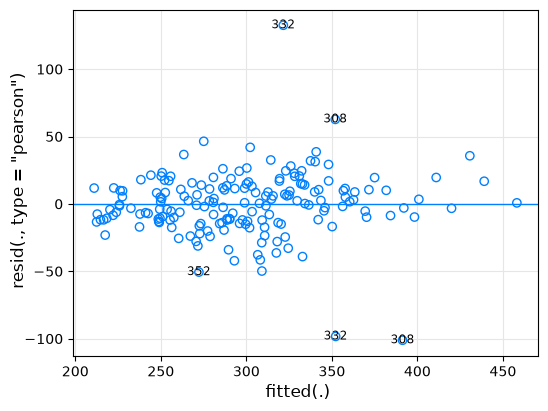

In [12]:
fig = fm1.plot(id=0.05)

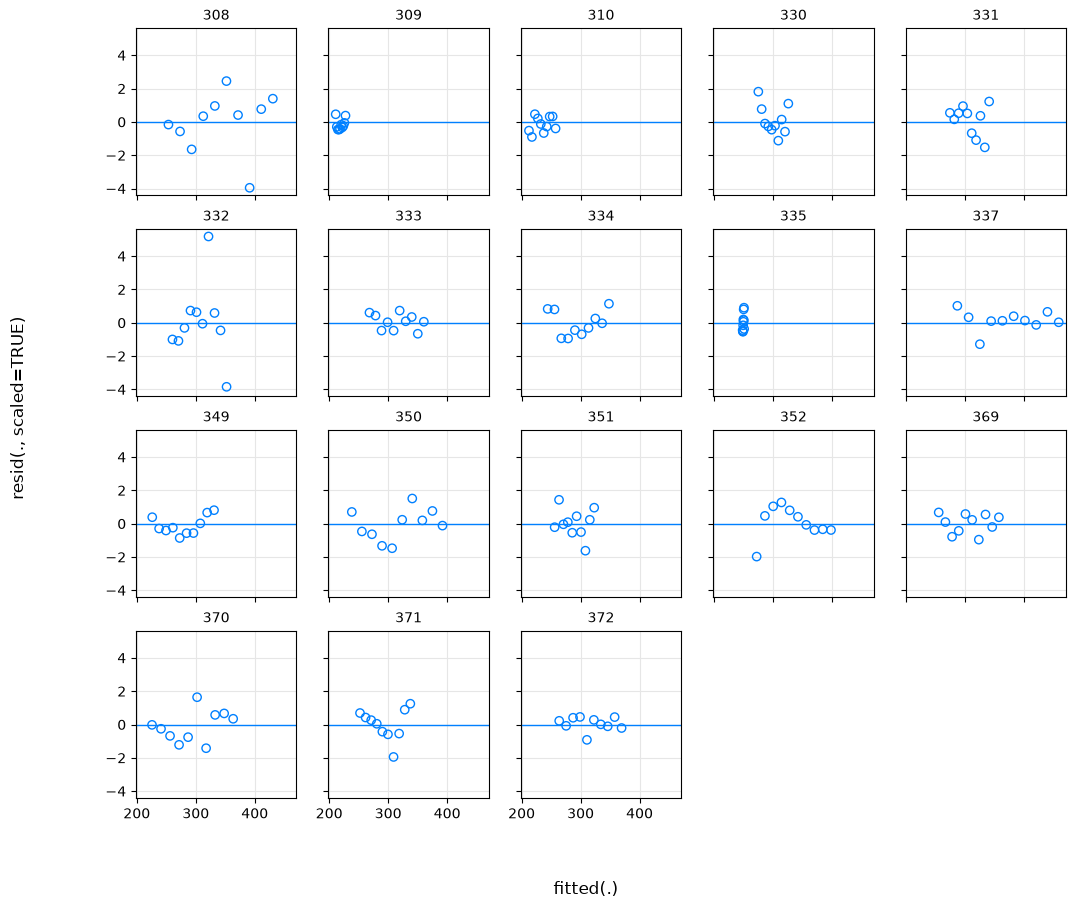

In [13]:
# plot.merMod accepts lattice-style formulas: '.' is the model, data columns are available,
# '| g' gives one panel per level of g
fig = fm1.plot("resid(., scaled=TRUE) ~ fitted(.) | Subject", abline=0)

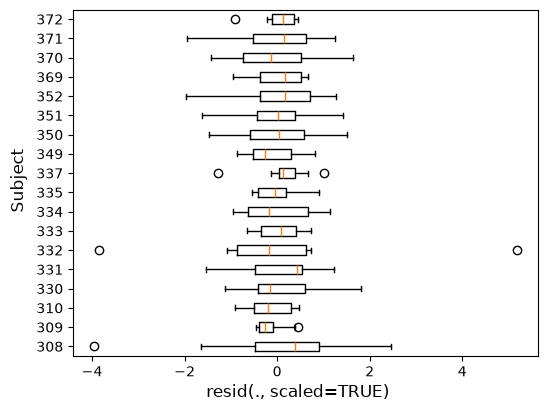

In [14]:
fig = fm1.plot("Subject ~ resid(., scaled=TRUE)")     # box plots of the residuals by subject

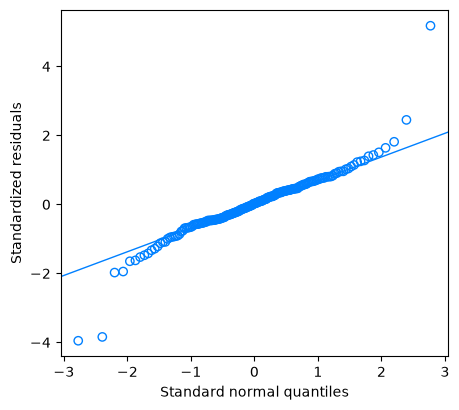

In [15]:
fig = fm1.qqmath()          # qqmath(fm1): normal QQ plot of the standardized residuals

The "caterpillar plot" `dotplot(ranef(fm1, condVar = TRUE))`: the conditional modes with 95%
prediction intervals from the conditional variances, subjects sorted by their intercept.
As in lattice, both panels share the x-axis (`scales_free=True` frees them). `qqmath(ranef(.))`
plots the conditional modes against normal quantiles.

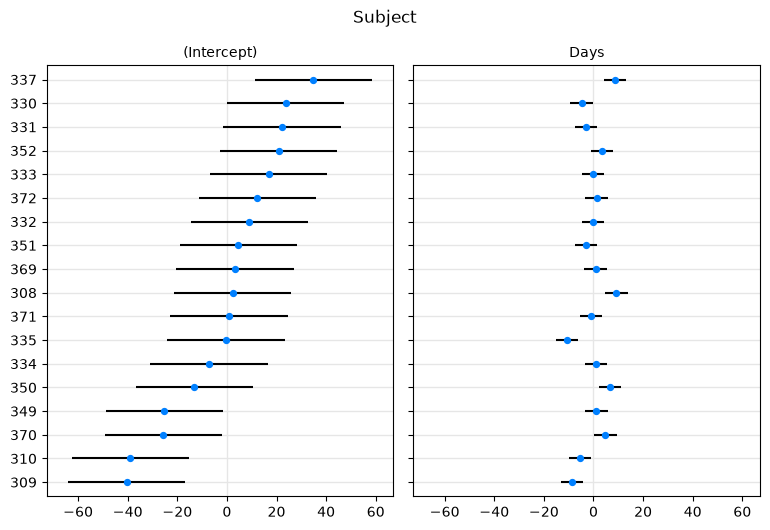

In [16]:
figs = re1.dotplot()          # dict: grouping factor -> Figure (lattice returns a list)

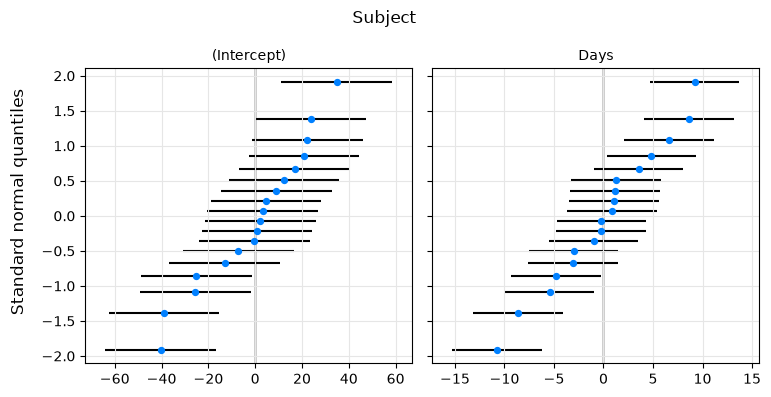

In [17]:
figs_qq = re1.qqmath()

### Check against R

The plotted coordinates are compared with the `panel.args` of the lattice objects created in R
(`plot(fm1)`, `dotplot(ranef(fm1))$Subject`, `qqmath(ranef(fm1))$Subject`).

In [18]:
# plot(fm1): x = fitted, y = Pearson residuals; axis labels as in R
fig = fm1.plot()
xy = fig.axes[0].collections[0].get_offsets()
assert_allclose(xy[:, 0], R["plot_fm1"]["x"], rtol=1e-6)
assert_allclose(xy[:, 1], R["plot_fm1"]["y"], rtol=1e-6, atol=1e-6)
assert fig._supxlabel.get_text() == R["plot_fm1"]["xlab"]
assert fig._supylabel.get_text() == R["plot_fm1"]["ylab"]

# identified points
fig = fm1.plot(id=0.05)
assert [t.get_text() for t in fig.axes[0].texts] == R["plot_fm1_id"]["labels"]

# panels by Subject
fig = fm1.plot("resid(., scaled=TRUE) ~ fitted(.) | Subject", abline=0)
vis = [a for a in fig.axes if a.get_visible()]
assert [a.get_title() for a in vis] == R["plot_fm1_panels"]["levels"]
assert [len(a.collections[0].get_offsets()) for a in vis] == R["plot_fm1_panels"]["n"]

# dotplot: level order, panels, x limits (lattice prepanel + axis padding) and plotted points
d = R["dotplot_fm1"]
fig = re1.dotplot()["Subject"]
assert [a.get_title() for a in fig.axes] == d["panels"]
assert [t.get_text() for t in fig.axes[0].get_yticklabels()] == d["levels"]
for k, a in enumerate(fig.axes):
    pts = a.collections[-1].get_offsets()
    assert_allclose(pts[:, 0], d["x"][k], rtol=1e-6, atol=1e-6)
    assert [d["levels"][int(round(y)) - 1] for y in pts[:, 1]] == d["y"][k]
    assert_allclose(a.get_xlim(), d["xlim"], rtol=1e-6)
from lme4.plots import asDf0
assert_allclose(asDf0(re1, "Subject")["se"].to_numpy(), d["se"], rtol=1e-6)

# qqmath(ranef): x = sorted conditional modes, y = normal quantiles
q = R["qqmath_fm1"]
fig = re1.qqmath()["Subject"]
for k, a in enumerate(fig.axes):
    pts = a.collections[-1].get_offsets()
    assert_allclose(pts[:, 0], np.sort(q["x"][k]), rtol=1e-6, atol=1e-6)
    assert_allclose(pts[:, 1], q["y"][k], rtol=1e-12)
# qqmath(fm1): the residuals
assert_allclose(np.sort(fm1.qqmath().axes[0].collections[0].get_offsets()[:, 1]),
                np.sort(R["qqmath_resid"]["x"]), rtol=1e-6, atol=1e-6)
plt.close("all")
print("plots agree with R")

plots agree with R


## REML versus maximum likelihood

`update(fm1, REML = FALSE)` refits by maximum likelihood. The fixed effects of a balanced
design are unchanged, but ML variance estimates are smaller (REML corrects for the degrees of
freedom used by $\hat\beta$), and the standard errors shrink accordingly.

In [19]:
fm1_ML = fm1.update(REML=False)
print(fm1_ML.summary())

Linear mixed model fit by maximum likelihood  ['lmerMod']
Formula: Reaction ~ Days + (Days | Subject)
   Data: sleepstudy

      AIC       BIC    logLik -2*log(L)  df.resid 
   1763.9    1783.1    -876.0    1751.9       174 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.9416 -0.4656  0.0289  0.4636  5.1793 

Random effects:
 Groups   Name        Variance Std.Dev. Corr 
 Subject  (Intercept) 565.51   23.780        
          Days         32.68    5.717   0.08 
 Residual             654.94   25.592        
Number of obs: 180, groups:  Subject, 18

Fixed effects:
            Estimate Std. Error t value
(Intercept)  251.405      6.632  37.906
Days          10.467      1.502   6.968

Correlation of Fixed Effects:
     (Intr)
Days -0.138


In [20]:
def components(m):
    vc = m.VarCorr().as_data_frame()
    s = pd.Series(vc["sdcor"].to_numpy(), index=vc["grp"] + ":" + vc["var1"].fillna("") + ":" + vc["var2"].fillna(""))
    return pd.concat([m.fixef(), s])

pd.DataFrame({"REML": components(fm1), "ML": components(fm1_ML)})

,REML,ML
(Intercept),251.405105,251.405105
Days,10.467286,10.467286
Subject:(Intercept):,24.740658,23.780468
Subject:Days:,5.922138,5.716828
Subject:Days:(Intercept),0.065551,0.081332
Residual::,25.591796,25.591824


### Check against R

The ML deviance agrees with R to better than `1e-10` relative, but `theta` differs in the
fifth significant digit: the ML deviance surface of this model is very flat around the
optimum, and the optimizer (`nloptwrap`, BOBYQA with relative tolerances ~1e-6 to 1e-8)
stops at slightly different points in R and Python because of rounding at the 1e-15 level
in the sparse Cholesky factor. Evaluating the profiled deviance function at R's `theta`
shows that both points are equally optimal (Python's is in fact lower by ~2e-8), so
`theta` and the quantities derived from it are compared with `rtol=1e-3`.

In [21]:
check_fit(fm1_ML, R["fm1_ML"], rtol=1e-3)
devfun = fm1_ML.as_function()                 # profiled deviance as a function of theta
d_py, d_R = devfun(fm1_ML.theta), devfun(np.array(R["fm1_ML"]["theta"]))
print(f"deviance at Python's theta: {d_py:.10f}\ndeviance at R's theta:      {d_R:.10f}")
assert_allclose(d_R, R["fm1_ML"]["deviance"], rtol=1e-10)   # same function in both
assert d_py <= d_R + 1e-7
assert_allclose(fm1_ML.fixef().to_numpy(), list(R["fm1_ML"]["fixef"].values()), rtol=1e-8)
assert_allclose(np.asarray(fm1_ML.vcov()), R["fm1_ML"]["vcov"], rtol=1e-3)
print("fm1_ML agrees with R")

deviance at Python's theta: 1751.9393444647
deviance at R's theta:      1751.9393444890
fm1_ML agrees with R


## Uncorrelated random effects `(Days || Subject)` and model comparison

The double bar expands to `(1 | Subject) + (0 + Days | Subject)`: independent random
intercepts and slopes (the stored formula is the expanded one, as in R). The second term
appears as `Subject.1` in `VarCorr`. In the symbolic API the double bar is the method
`Days.dbar(Subject)`.

In [22]:
fm2 = lmer("Reaction ~ Days + (Days || Subject)", data=sleepstudy)
fm2_sym = lmer(Reaction == Days + Days.dbar(Subject), data=sleepstudy)
assert fm2_sym.REMLcrit() == fm2.REMLcrit()
print(fm2.summary())

Linear mixed model fit by REML ['lmerMod']
Formula: Reaction ~ Days + ((1 | Subject) + (0 + Days | Subject))
   Data: sleepstudy

REML criterion at convergence: 1743.7

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.9626 -0.4625  0.0204  0.4653  5.1860 

Random effects:
 Groups    Name        Variance Std.Dev.
 Subject   (Intercept) 627.57   25.051  
 Subject.1 Days         35.86    5.988  
 Residual              653.58   25.565  
Number of obs: 180, groups:  Subject, 18

Fixed effects:
            Estimate Std. Error t value
(Intercept)  251.405      6.885  36.513
Days          10.467      1.560   6.712

Correlation of Fixed Effects:
     (Intr)
Days -0.184


`anova()` refits REML fits by ML and performs likelihood ratio tests. The correlation
parameter of `fm1` is far from significant ($p \approx 0.8$), while the random slope is
essentially required (compare with a random-intercept-only model `fm0`).

In [23]:
a12 = fm1.anova(fm2, model_names=["fm1", "fm2"])
a12

refitting model(s) with ML (instead of REML)


,npar,AIC,BIC,logLik,-2*log(L),Chisq,Df,Pr(>Chisq)
fm2,5,1762.003255,1777.968039,-876.001628,1752.003255,NaN,NaN,NaN
fm1,6,1763.939344,1783.097086,-875.969672,1751.939344,0.063911,1.0,0.800418


In [24]:
fm0 = lmer("Reaction ~ Days + (1 | Subject)", data=sleepstudy)
a021 = fm0.anova(fm2, fm1, model_names=["fm0", "fm2", "fm1"])
a021

refitting model(s) with ML (instead of REML)


,npar,AIC,BIC,logLik,-2*log(L),Chisq,Df,Pr(>Chisq)
fm0,4,1802.078643,1814.850470,-897.039322,1794.078643,NaN,NaN,NaN
fm2,5,1762.003255,1777.968039,-876.001628,1752.003255,42.075388,1.0,8.782158e-11
fm1,6,1763.939344,1783.097086,-875.969672,1751.939344,0.063911,1.0,8.004184e-01


In [25]:
# refit=False compares the REML criteria directly (valid here: same fixed effects)
fm0.anova(fm2, refit=False, model_names=["fm0", "fm2"])

,npar,AIC,BIC,logLik,-2*log(L),Chisq,Df,Pr(>Chisq)
fm0,4,1794.465085,1807.236913,-893.232543,1786.465085,NaN,NaN,NaN
fm2,5,1753.669294,1769.634078,-871.834647,1743.669294,42.795792,1.0,6.076273e-11


### Check against R

In [26]:
check_fit(fm2, R["fm2"])
check_ranef(fm2, R["fm2"])
check_fit(fm2_sym, R["fm2"])
assert str(fm2.formula()) == R["fm2"]["formula"], (str(fm2.formula()), R["fm2"]["formula"])
check_fit(fm0, R["fm0"])
check_ranef(fm0, R["fm0"])

assert list(a12.index) == R["anova_fm1_fm2"]["models"]
check_anova(a12, R["anova_fm1_fm2"])
assert list(a021.index) == R["anova_fm0_fm2_fm1"]["models"]
check_anova(a021, R["anova_fm0_fm2_fm1"])
check_anova(fm0.anova(fm2, refit=False, model_names=["fm0", "fm2"]), R["anova_fm0_fm2_REML"])
print("fm2, fm0 and anova() agree with R")

fm2, fm0 and anova() agree with R

## `?sleepstudy`: fitting a subset

`subset=` takes the same expression as in R (here as a string). The independent model
`(1|Subject) + (0+Days|Subject)` is the explicit form of `(Days || Subject)`.

In [27]:
fm1s = lmer("Reaction ~ Days + (Days|Subject)", data=sleepstudy, subset="Days >= 2")
fm2s = lmer("Reaction ~ Days + (1|Subject) + (0+Days|Subject)", data=sleepstudy, subset="Days >= 2")
print(fm1s)
print(fm2s)

Linear mixed model fit by REML ['lmerMod']
Formula: Reaction ~ Days + (Days | Subject)
   Data: sleepstudy
 Subset: Days >= 2
REML criterion at convergence: 1404.094
Random effects:
 Groups   Name        Std.Dev. Corr  
 Subject  (Intercept) 31.507         
          Days         6.766   -0.25 
 Residual             25.526         
Number of obs: 144, groups:  Subject, 18
Fixed Effects:
(Intercept)         Days  
     245.10        11.44  
Linear mixed model fit by REML ['lmerMod']
Formula: Reaction ~ Days + (1 | Subject) + (0 + Days | Subject)
   Data: sleepstudy
 Subset: Days >= 2
REML criterion at convergence: 1404.626
Random effects:
 Groups    Name        Std.Dev.
 Subject   (Intercept) 28.843  
 Subject.1 Days         6.285  
 Residual              25.747  
Number of obs: 144, groups:  Subject, 18
Fixed Effects:
(Intercept)         Days  
     245.10        11.44  


### Check against R

As for `fm1_ML` above, the REML criteria agree to `rtol=1e-8`, but the optimizer stops at
slightly different `theta` on a flat surface (relative differences ~3e-4 for `fm1s`, ~4e-6
for `fm2s`). Evaluating the REML criterion at R's `theta` confirms that both points are
equally optimal, so the estimates of these two fits are compared with `rtol=1e-3`.

In [28]:
for m, key in [(fm1s, "fm1s"), (fm2s, "fm2s")]:
    check_fit(m, R[key], rtol=1e-3)
    devfun = m.as_function()
    d_py, d_R = devfun(m.theta), devfun(np.array(R[key]["theta"]))
    print(f"{key}: REML criterion at Python's theta {d_py:.10f}, at R's theta {d_R:.10f}")
    assert_allclose(d_R, R[key]["REMLcrit"], rtol=1e-10)
    assert abs(d_py - d_R) < 1e-6
print("subset fits agree with R")

fm1s: REML criterion at Python's theta 1404.0943653557, at R's theta 1404.0943654245
fm2s: REML criterion at Python's theta 1404.6256344935, at R's theta 1404.6256344979
subset fits agree with R


## `Dyestuff` and `Dyestuff2`: a singular fit

`Dyestuff` gives yields of dyestuff from 5 preparations in each of 6 batches of an
intermediate product. `Dyestuff2` is simulated data with the same structure in which the
between-batch variability is small relative to the residual variability. Its REML estimate
of the batch variance is exactly zero: the fit lies on the boundary of the parameter space
(`theta = 0`), lme4 reports a *boundary (singular) fit*, and `isSingular()` is `True`. The
model then reduces to a simple linear model with the same $\hat\sigma$ as `lm(Yield ~ 1)`.

In [29]:
Dyestuff = load_dataset("Dyestuff")
Dyestuff2 = load_dataset("Dyestuff2")
fm1d = lmer("Yield ~ 1|Batch", data=Dyestuff)
print(fm1d.summary())

Linear mixed model fit by REML ['lmerMod']
Formula: Yield ~ 1 | Batch
   Data: Dyestuff

REML criterion at convergence: 319.7

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-1.4117 -0.7634  0.1418  0.7792  1.8296 

Random effects:
 Groups   Name        Variance Std.Dev.
 Batch    (Intercept) 1764     42.00   
 Residual             2451     49.51   
Number of obs: 30, groups:  Batch, 6

Fixed effects:
            Estimate Std. Error t value
(Intercept)  1527.50      19.38    78.8


In [30]:
fm2d = lmer("Yield ~ 1|Batch", data=Dyestuff2)
print(fm2d)
print("isSingular:", fm2d.isSingular(), "  theta:", fm2d.theta)

Linear mixed model fit by REML ['lmerMod']
Formula: Yield ~ 1 | Batch
   Data: Dyestuff2
REML criterion at convergence: 161.8283
Random effects:
 Groups   Name        Std.Dev.
 Batch    (Intercept) 0.000   
 Residual             3.716   
Number of obs: 30, groups:  Batch, 6
Fixed Effects:
(Intercept)  
      5.666  
optimizer (nloptwrap) convergence code: 0 (OK) ; 0 optimizer warnings; 1 lme4 warnings 
isSingular: True   theta: [0.]


boundary (singular) fit: see help('isSingular')


In [31]:
# the singular fit has the residual SD of the intercept-only linear model
y = Dyestuff2["Yield"].to_numpy()
print("sigma(fm2d) =", fm2d.sigma(), "  sd(Yield) =", y.std(ddof=1))

sigma(fm2d) = 3.715684274475727   sd(Yield) = 3.7156842744757266


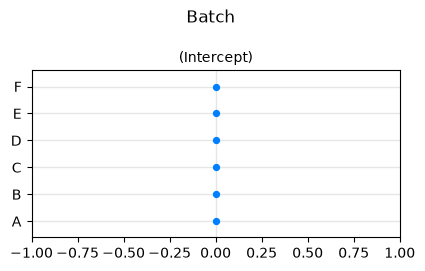

In [32]:
figs = fm2d.ranef(condVar=True).dotplot()     # all conditional modes are 0 for a singular fit

### Check against R

In [33]:
check_fit(fm1d, R["dye1"])
check_ranef(fm1d, R["dye1"])
check_fit(fm1d.update(REML=False), R["dye1_ML"])
check_fit(fm2d, R["dye2"])
assert fm2d.isSingular() and R["dye2"]["isSingular"]
assert_allclose(fm2d.theta, 0, atol=1e-10)
assert_allclose(fm2d.sigma(), R["dye2_lm_sigma"], rtol=1e-6)
assert_allclose(y.std(ddof=1), R["dye2_lm_sigma"], rtol=1e-12)
print("Dyestuff fits agree with R")

Dyestuff fits agree with R


## Summary

All fits (REML and ML criteria, fixed effects, standard errors, variance components,
conditional modes and their conditional standard deviations, `coef`, `anova` tables), and the
data drawn by the diagnostic plots, agree with R's lme4 2.1.0: objective functions to
`rtol=1e-8`, estimates to `rtol=1e-6`.